# CIFAR-10 FCN

## 1. Business Understanding

Tarkoitus on oppia käyttämään ja arvioimaan neuroverkko tekniikoita CIFAR-10 datasetin avulla. Tässä työkirjassa käytämmen FCN (Fully Connected Network) mallia.

## 2. Data Understanding

In [57]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

In [58]:
import keras
from keras import layers
print(keras.__version__, keras.backend.backend())
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import to_categorical
import pandas as pd
import time

#AI ehdottama muutos jotta koulutus kayttaisi amd gputa (ei muuttanut koulutusaikoja)

import tensorflow as tf
tf.config.set_visible_devices([], "GPU")

3.15.1 tensorflow


In [59]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

In [60]:
print(f'x_train shape: {x_train.shape}')
print(f'x_test shape:  {x_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape:  {y_test.shape}')

x_train shape: (50000, 32, 32, 3)
x_test shape:  (10000, 32, 32, 3)
y_train shape: (50000, 1)
y_test shape:  (10000, 1)


Data pitää sisällään 60,000 32x32 värikuvaa. Se on jaettu koulutus ja testi joukkoihin. Koulutusjoukossa on 50,000 ja testijoukossa 10,000 kuvaa. Kuvilla on 10 eri luokkaa. `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship` ja `truck`. Luokilla ei ole päällekkäisyyksiä, esim `automobile` ja `truck` luokissa ei ole samantyyppisiä autoja.
[lähde](https://cave.cs.toronto.edu/kriz/cifar.html)

## 3. Data Preprocessing

In [80]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

mean = x_train.mean(axis=(0, 1, 2))
std = x_train.std(axis=(0, 1, 2))
print("mean:", mean)
print("std: ", std)

x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

X_train = x_train.reshape(50000, 3072)
X_test = x_test.reshape(10000, 3072)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# --- Data augmentation: horizontal flips (new variables only) ---

# Flip training images horizontally
x_train_flipped = np.flip(x_train, axis=2).copy()

# Flatten flipped images
X_train_flipped = x_train_flipped.reshape(50000, 3072)

# Reuse the same one-hot labels
y_train_flipped = y_train.copy()

# Combined dataset: original + flipped images
X_train_augmented = np.concatenate(
    [X_train, X_train_flipped], axis=0
)
y_train_augmented = np.concatenate(
    [y_train, y_train_flipped], axis=0
)

mean: [0.4914009  0.48215896 0.4465308 ]
std:  [0.24703279 0.24348423 0.26158753]


## 4. Modeling

### Neuronien ja kerrosten määrien vertailu

Vertaillaan mallin suorityskykyä neuronien ja kerrosten määrän perusteella.
Kokeilussa on `512`, `256` ja `128` neuronin ensimmäinen kerros, toiseen kerroksen kokeiluilla neuronien määrä puolitetaan.

In [62]:
results = []
histories = {}
def build_model(units, n_layers):
    layers = [keras.Input(shape=(3072,))]
    width = units
    for _ in range(n_layers):
        layers.append(keras.layers.Dense(width, activation="relu"))
        width = max(width // 2, 16)
    layers.append(keras.layers.Dense(10, activation="softmax"))
    model = keras.Sequential(layers)
    model.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

for units in [128, 256, 512]:
    for n_layers in [1, 2]:
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,restore_best_weights=True)]
        keras.utils.set_random_seed(42)
        model = build_model(units, n_layers)

        t0 = time.perf_counter()
        history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                            validation_split=0.2, verbose=0, callbacks=callbacks)
        train_time = time.perf_counter() - t0

        test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
        key = f"{units} neuronia, {n_layers} kerrosta"
        histories[key] = history.history
        best_epoch = int(np.argmin(history.history["val_loss"]))

        results.append({
            "neuronit": units,
            "kerrokset": n_layers,
            "parametreja": model.count_params(),
            "aika_s": train_time / len(history.history["loss"]),
            "paras_epookki": best_epoch + 1,
            "epookkeja_ajettu": len(history.history["loss"]),
            "train_acc": history.history["accuracy"][best_epoch],
            "val_acc": history.history["val_accuracy"][best_epoch],
            "ero_train_val": history.history["accuracy"][best_epoch]
                     - history.history["val_accuracy"][best_epoch],
            "test_acc": test_acc,
        })
        print(key, "->", round(test_acc, 4), f"({train_time/len(history.history['loss']):.1f} s)")
df = pd.DataFrame(results)

128 neuronia, 1 kerrosta -> 0.4737 (1.8 s)
128 neuronia, 2 kerrosta -> 0.4723 (1.8 s)
256 neuronia, 1 kerrosta -> 0.4486 (2.9 s)
256 neuronia, 2 kerrosta -> 0.4776 (3.0 s)
512 neuronia, 1 kerrosta -> 0.4605 (5.5 s)
512 neuronia, 2 kerrosta -> 0.4807 (6.1 s)


In [63]:
df

,neuronit,kerrokset,parametreja,aika_s,paras_epookki,epookkeja_ajettu,train_acc,val_acc,ero_train_val,test_acc
0,128,1,394634,1.757432,4,7,0.538875,0.4756,0.063275,0.4737
1,128,2,402250,1.784410,4,7,0.522525,0.4682,0.054325,0.4723
2,256,1,789258,2.865854,2,5,0.481550,0.4553,0.026250,0.4486
3,256,2,820874,2.967859,4,7,0.531900,0.4686,0.063300,0.4776
4,512,1,1578506,5.529533,2,5,0.485600,0.4608,0.024800,0.4605
5,512,2,1707274,6.089437,4,7,0.533900,0.4760,0.057900,0.4807


Testeistä selviää että mallin koko ei juurikaan paranna mallin suorituskykyä, mutta suuremmalla mallilla jossa `512` neuronia ja `2` kerrosta aika on yli kaksinkertainen per epoch. `val_acc` on paras `256` neuronilla jossa 2 kerrosta, toisessa kerroksessa `128` neuronia.

In [64]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
full_history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2)
print("\n")
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 4s - 6ms/step - accuracy: 0.3802 - loss: 1.7982 - val_accuracy: 0.4191 - val_loss: 1.6447
Epoch 2/20
625/625 - 3s - 5ms/step - accuracy: 0.4590 - loss: 1.5354 - val_accuracy: 0.4537 - val_loss: 1.5621
Epoch 3/20
625/625 - 3s - 5ms/step - accuracy: 0.5001 - loss: 1.4122 - val_accuracy: 0.4627 - val_loss: 1.5569
Epoch 4/20
625/625 - 3s - 5ms/step - accuracy: 0.5332 - loss: 1.3247 - val_accuracy: 0.4697 - val_loss: 1.5434
Epoch 5/20
625/625 - 3s - 5ms/step - accuracy: 0.5577 - loss: 1.2503 - val_accuracy: 0.4723 - val_loss: 1.5563
Epoch 6/20
625/625 - 3s - 5ms/step - accuracy: 0.5842 - loss: 1.1786 - val_accuracy: 0.4734 - val_loss: 1.5956
Epoch 7/20
625/625 - 3s - 5ms/step - accuracy: 0.6037 - loss: 1.1147 - val_accuracy: 0.4718 - val_loss: 1.6314
Epoch 8/20
625/625 - 3s - 5ms/step - accuracy: 0.6241 - loss: 1.0606 - val_accuracy: 0.4761 - val_loss: 1.6475
Epoch 9/20
625/625 - 3s - 5ms/step - accuracy: 0.6468 - loss: 0.9939 - val_accuracy: 0.4783 - val_loss: 1.6985
E

## Learning rate

Seuraavassa solussa tutkin Learning raten muutoksen vaikutusta validation loss ja validation accurcyn. Käytän yllä määriteltyä callback functiota rajoittamaan epochien määrää

Hypoteesi: luultavasti ephocien määrä kasvaa kun pienennän learning ratea, sillä painokertoimet muuttuvat hitaammin. Periaatteessa voisi tulla parempia tuloksia jos edellä käytetyn learning raten "resoluutio" ei ollut tarpeeksi tarkka. Luulen että learning raten kasvattaminen huonontaa tuloksia mutta nopeuttaa koulutusta (vähentämällä epochien määrää).

In [73]:
#pienempi learning 0.0001 rate adam default on 0.001
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history1 = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#suurempi learning rate

model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history2 = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#pienin learning rate 0.00001

model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history3 = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 4s - 6ms/step - accuracy: 0.3934 - loss: 1.7309 - val_accuracy: 0.4317 - val_loss: 1.6218
Epoch 2/20
625/625 - 3s - 5ms/step - accuracy: 0.4850 - loss: 1.4853 - val_accuracy: 0.4607 - val_loss: 1.5518
Epoch 3/20
625/625 - 3s - 5ms/step - accuracy: 0.5283 - loss: 1.3708 - val_accuracy: 0.4708 - val_loss: 1.5189
Epoch 4/20
625/625 - 3s - 5ms/step - accuracy: 0.5596 - loss: 1.2843 - val_accuracy: 0.4804 - val_loss: 1.4981
Epoch 5/20
625/625 - 3s - 5ms/step - accuracy: 0.5870 - loss: 1.2130 - val_accuracy: 0.4904 - val_loss: 1.4873
Epoch 6/20
625/625 - 3s - 5ms/step - accuracy: 0.6101 - loss: 1.1502 - val_accuracy: 0.4928 - val_loss: 1.4800
Epoch 7/20
625/625 - 3s - 5ms/step - accuracy: 0.6323 - loss: 1.0919 - val_accuracy: 0.4919 - val_loss: 1.4805
Epoch 8/20
625/625 - 3s - 5ms/step - accuracy: 0.6516 - loss: 1.0395 - val_accuracy: 0.4971 - val_loss: 1.4826
Epoch 9/20
625/625 - 3s - 5ms/step - accuracy: 0.6704 - loss: 0.9907 - val_accuracy: 0.4994 - val_loss: 1.4887



tulokset: Learning rate 0.0001 oli parempi kuin vakio 0.001  (val_accuracy: 0.5022 vs val_accuracy: 0.4691). Learning rate 0.01 oli aivan liian suuri ja validation accuracy on lähellä satunnaista arvausta. Learnin rate 0.00001 oli liian tarkka ja 20 epochia ei riittänyt kouluttamaan mallia parhaaseen muotoon. 

Ylisovittamista varsinkin accuracy: 0.6101 vs val_accuracy: 0.4928
0.00001 malli validation accuracy ei ole yhtä hyvä mutta malli ei ole niin ylisovitettu: accuracy: 0.5639 vs val_accuracy: 0.4787

## Batch size

Batch size vaikuttaa gradientin kohinaan. Jos olen ymmärtänyt oikein suuremmalla batch sizellä malli ottaa huomioon enemmän kuvia kun se laskee loss arvoa. Nyt kun painokertoimia muutetaan ja huomataan vaikutus loss arvoon se ei ole vain yhden kuvan perusteella. 

In [72]:
#16 batch size
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train, y_train, epochs=20, batch_size=16,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#32 batch size
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train, y_train, epochs=20, batch_size=32,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#128 batch size
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train, y_train, epochs=20, batch_size=128,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
2500/2500 - 12s - 5ms/step - accuracy: 0.4031 - loss: 1.7171 - val_accuracy: 0.4310 - val_loss: 1.6175
Epoch 2/20
2500/2500 - 11s - 4ms/step - accuracy: 0.4905 - loss: 1.4623 - val_accuracy: 0.4618 - val_loss: 1.5425
Epoch 3/20
2500/2500 - 11s - 4ms/step - accuracy: 0.5404 - loss: 1.3311 - val_accuracy: 0.4755 - val_loss: 1.5159
Epoch 4/20
2500/2500 - 10s - 4ms/step - accuracy: 0.5764 - loss: 1.2262 - val_accuracy: 0.4881 - val_loss: 1.5011
Epoch 5/20
2500/2500 - 11s - 4ms/step - accuracy: 0.6126 - loss: 1.1374 - val_accuracy: 0.4917 - val_loss: 1.4942
Epoch 6/20
2500/2500 - 11s - 4ms/step - accuracy: 0.6421 - loss: 1.0566 - val_accuracy: 0.4945 - val_loss: 1.5076
Epoch 7/20
2500/2500 - 11s - 4ms/step - accuracy: 0.6683 - loss: 0.9852 - val_accuracy: 0.4998 - val_loss: 1.5236
Epoch 8/20
2500/2500 - 10s - 4ms/step - accuracy: 0.6946 - loss: 0.9191 - val_accuracy: 0.5002 - val_loss: 1.5458


Epoch 1/20
1250/1250 - 6s - 5ms/step - accuracy: 0.3940 - loss: 1.7261 - val_accuracy:

Ainakin Aleksin tietokone pystyy käyttämään suurempaa batch sizea nopeuttamaan epocheja. Batch size ei vaikuttanut merkittävästi tarkasteltaviin arvoihin.

## Data augmentation

lisätään dataan alkioiden peilikuvia. Näin tuplataan training setin koko.

In [82]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train_augmented, y_train_augmented, epochs=20, batch_size=128,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 4s - 7ms/step - accuracy: 0.4125 - loss: 1.6682 - val_accuracy: 0.4570 - val_loss: 1.5521
Epoch 2/20
625/625 - 4s - 6ms/step - accuracy: 0.4958 - loss: 1.4447 - val_accuracy: 0.4890 - val_loss: 1.4756
Epoch 3/20
625/625 - 4s - 6ms/step - accuracy: 0.5338 - loss: 1.3446 - val_accuracy: 0.5070 - val_loss: 1.4294
Epoch 4/20
625/625 - 4s - 6ms/step - accuracy: 0.5603 - loss: 1.2724 - val_accuracy: 0.5174 - val_loss: 1.4053
Epoch 5/20
625/625 - 4s - 6ms/step - accuracy: 0.5824 - loss: 1.2144 - val_accuracy: 0.5254 - val_loss: 1.3856
Epoch 6/20
625/625 - 4s - 6ms/step - accuracy: 0.6013 - loss: 1.1639 - val_accuracy: 0.5294 - val_loss: 1.3724
Epoch 7/20
625/625 - 4s - 6ms/step - accuracy: 0.6169 - loss: 1.1196 - val_accuracy: 0.5347 - val_loss: 1.3636
Epoch 8/20
625/625 - 4s - 6ms/step - accuracy: 0.6319 - loss: 1.0801 - val_accuracy: 0.5375 - val_loss: 1.3591
Epoch 9/20
625/625 - 4s - 6ms/step - accuracy: 0.6438 - loss: 1.0434 - val_accuracy: 0.5389 - val_loss: 1.3568
E

Malli validation accuracy parantui melkein 5% mutta tämä saattaa johtua siitä että nyt validaatio data voi sisältää alkuperäisen datan peilikuvia.

## Dropout

Kaikissa malleissa ylisovittaminen on ollut ongelma. dropoutin pitäisi parantaa tätä.

In [84]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),

    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.2),

    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train_augmented, y_train_augmented, epochs=50, batch_size=128,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/50
625/625 - 5s - 8ms/step - accuracy: 0.3333 - loss: 1.9038 - val_accuracy: 0.4335 - val_loss: 1.6398
Epoch 2/50
625/625 - 4s - 7ms/step - accuracy: 0.4022 - loss: 1.6996 - val_accuracy: 0.4583 - val_loss: 1.5605
Epoch 3/50
625/625 - 4s - 7ms/step - accuracy: 0.4299 - loss: 1.6236 - val_accuracy: 0.4744 - val_loss: 1.5103
Epoch 4/50
625/625 - 4s - 6ms/step - accuracy: 0.4477 - loss: 1.5703 - val_accuracy: 0.4880 - val_loss: 1.4764
Epoch 5/50
625/625 - 4s - 7ms/step - accuracy: 0.4624 - loss: 1.5245 - val_accuracy: 0.4972 - val_loss: 1.4430
Epoch 6/50
625/625 - 4s - 7ms/step - accuracy: 0.4726 - loss: 1.4918 - val_accuracy: 0.5059 - val_loss: 1.4223
Epoch 7/50
625/625 - 4s - 7ms/step - accuracy: 0.4834 - loss: 1.4630 - val_accuracy: 0.5112 - val_loss: 1.4038
Epoch 8/50
625/625 - 4s - 7ms/step - accuracy: 0.4954 - loss: 1.4376 - val_accuracy: 0.5191 - val_loss: 1.3807
Epoch 9/50
625/625 - 4s - 7ms/step - accuracy: 0.5023 - loss: 1.4144 - val_accuracy: 0.5232 - val_loss: 1.3709
E

In [85]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=128,
    verbose=2
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

79/79 - 0s - 2ms/step - accuracy: 0.5716 - loss: 1.2231
Test loss: 1.2230643033981323
Test accuracy: 0.5716000199317932
Test accuracy: 57.16%


## 5. Evaluation

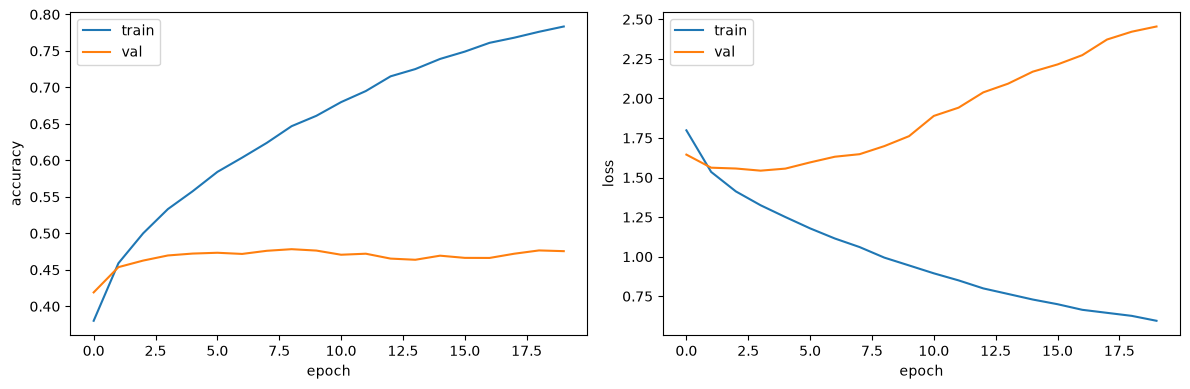

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(full_history.history["accuracy"], label="train")
axes[0].plot(full_history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(full_history.history["loss"], label="train")
axes[1].plot(full_history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

yllä olevista kuvaajista voimme päätellä `val_loss` noususta että malli ylioppii (overfit). Lisätään aikaisemppiin mallinkoulutuksiin callback joka pysäyttää ja palauttaa parametrit jolloin `val_loss` alkoi nousta.

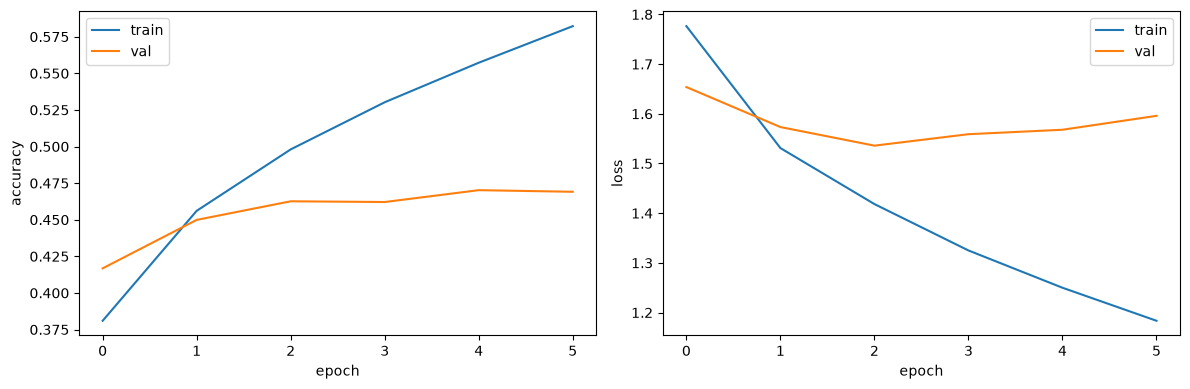

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

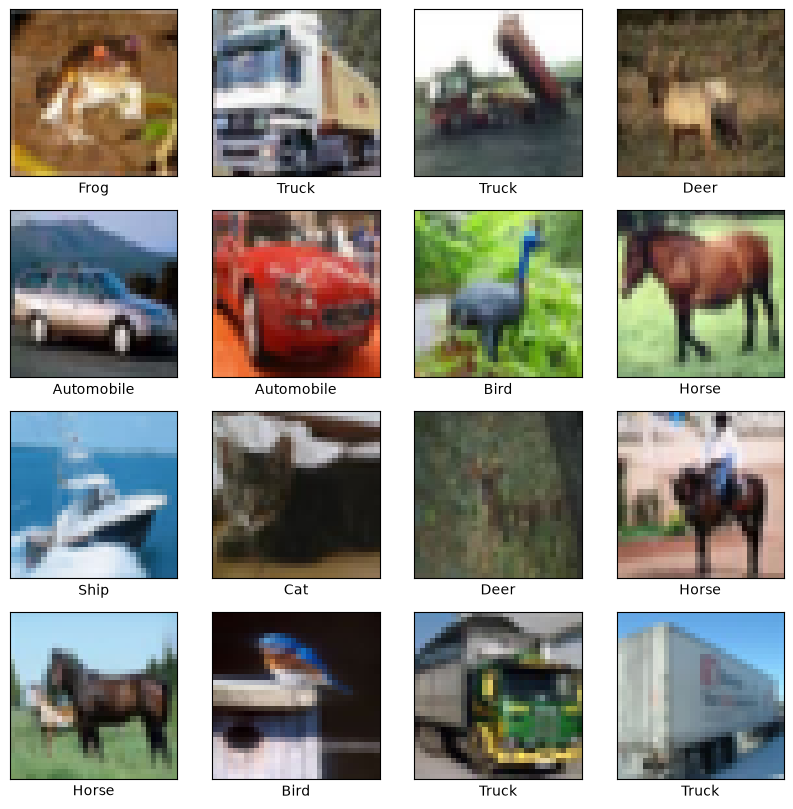

In [68]:
(x_train2, y_train2), (x_test2, y_test2) = keras.datasets.cifar10.load_data()

x_train2 = x_train2.astype("float32") / 255
x_test2 = x_test2.astype("float32") / 255

class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']

plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train2[i])
    plt.xlabel(class_names[y_train2[i][0]])
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 796us/step
(10000, 10) 1.0


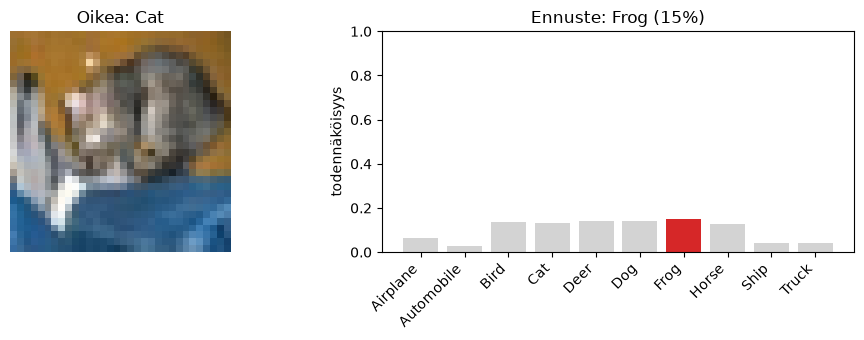

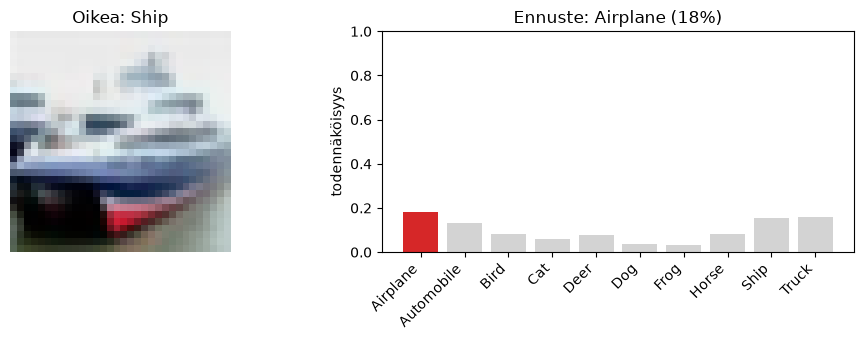

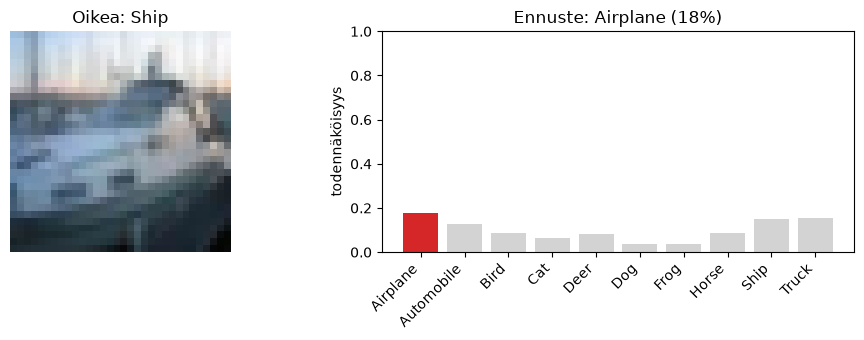

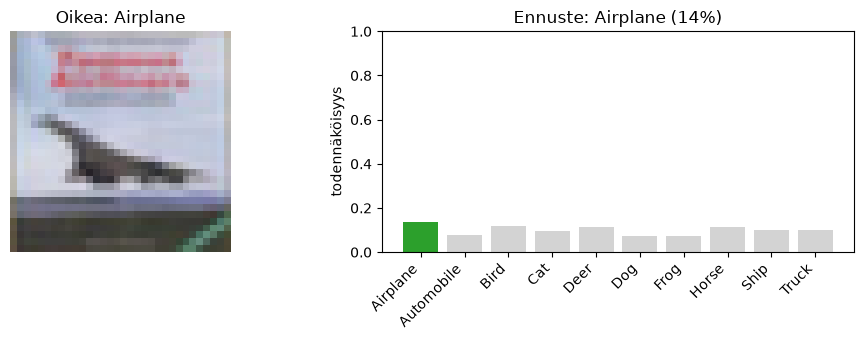

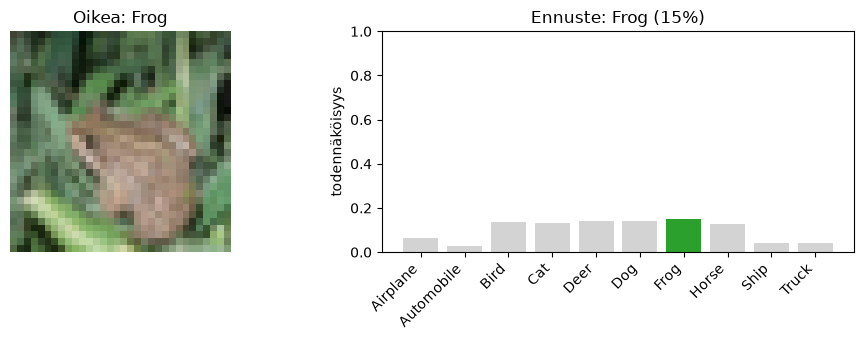

In [69]:
x_test_flat = x_test2.reshape(10000, 3072)
probs = model.predict(x_test_flat)
print(probs.shape, probs[0].sum())

(_, _), (x_test_img, y_test_int) = keras.datasets.cifar10.load_data()
x_test_img = x_test_img.astype("float32") / 255
y_test_int = y_test_int.flatten()

def plot_prediction(i, probs, images_img, true_labels):
    pred = np.argmax(probs[i])
    true = true_labels[i]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax1.imshow(images_img[i])
    ax1.axis("off")
    ax1.set_title(f"Oikea: {class_names[true]}")

    colors = ["lightgray"] * 10
    colors[pred] = "tab:red" if pred != true else "tab:green"
    ax2.bar(range(10), probs[i], color=colors)
    ax2.set_xticks(range(10))
    ax2.set_xticklabels(class_names, rotation=45, ha="right")
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("todennäköisyys")
    ax2.set_title(f"Ennuste: {class_names[pred]} ({probs[i][pred]:.0%})")

    plt.tight_layout()
    plt.show()

for i in range(5):
    plot_prediction(i, probs, x_test_img, y_test_int)

## Tekoälyn käyttö
tekoälyä on käytetty koodien kirjoittamisen ja eri funktioden toimninnan ymmärtämisen apuna.